En este ejercicio se construyó un ensamble de matrices de Wishart correlacionadas (CWOE) utilizando los parámetros \(N=300\), \(T=50\) y \(c=0.3\). A partir de estas matrices se generaron 500 realizaciones NSRSE de dimensión \(35\times35\), extrayendo submatrices principales. Posteriormente, se calcularon los autovalores de cada realización y se construyó un histograma normalizado para estudiar su distribución espectral. Finalmente, se compararon los resultados numéricos con la densidad teórica del CWOE, descrita por la ecuación (30) del artículo *Phys. Rev. E 88, 032115 (2013)*. Se observó una concordancia cualitativa en la región principal del espectro (*bulk*), así como la presencia de autovalores aislados asociados con las correlaciones del sistema.

In [9]:
import numpy as np 
import matplotlib.pyplot as plt
from scipy.linalg import sqrtm

In [10]:
N = 300
T = 50
c = 0.3

def matriz_D(N, T):
    D = np.random.normal(0, 1, size=(N, T))
    return D # Creamos una función que nos haga la matriz D 

def Xi(N, c):
    Xi = np.full((N,N),c, dtype= float) 
    """Este parte de aquí nos ayuda a crear la matriz de NxN, con el full llenamos los valores de c,
    y nada más rellenamos con unos en la diagonal"""
    np.fill_diagonal(Xi, 1)
    """Esta parte de aquí nos ayuda a rellenar con unos la diagonal"""
    return Xi

def X(N,T,c):
    D = matriz_D(N, T)
    Xi_mat = Xi(N, c)
    Xi_sqrt = sqrtm(Xi_mat)
    X = Xi_sqrt @ D
    return X
    # Creamos nuestra función que haga el calculo de X, para ello necesitamos una libreria scipy.linalg 

def C(N,T,c):
    X_math = X(N,T,c)
    C = (X_math @ X_math.T) / T
    return C
    # Creamos nuestra última matriz que hará comparar los datos

In [11]:
C(N,T,c).shape


(300, 300)

In [12]:
C_matriz = C(N, T, c)

print("Rango:", np.linalg.matrix_rank(C_matriz))

Rango: 50


Construimos las matrices NSRSE de 35x35

In [13]:
M = 500
d = 35
NSRE = []
for i in range(M):
    C_matriz = C(N, T, c)
    matriz_NSRE = C_matriz[:d,:d]
    NSRE.append(matriz_NSRE)

NSRE = np.array(NSRE)

In [14]:
print(NSRE.shape)

(500, 35, 35)


In [15]:
autovalores = []

for matriz in NSRE:
    eig = np.linalg.eigvalsh(matriz)
    autovalores.extend(eig)

autovalores = np.array(autovalores)
print(autovalores.shape)

(17500,)


Text(0, 0.5, 'Densidad espectral')

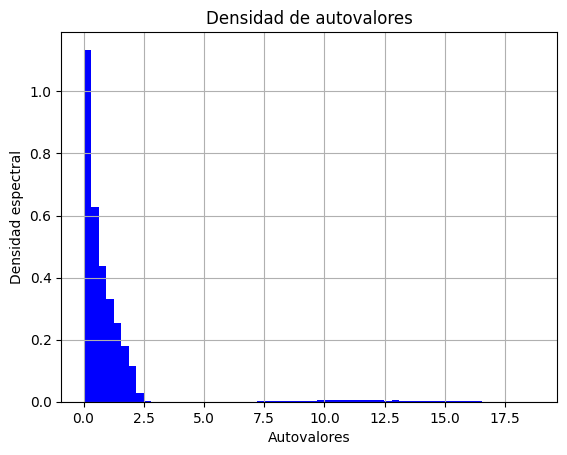

In [20]:
plt.hist(autovalores, bins = 60, color = "blue", density = True)
plt.grid()
plt.title("Densidad de autovalores")
plt.xlabel("Autovalores")
plt.ylabel("Densidad espectral")

ley de RMT para distribución de valores propios de CWOE 

In [22]:
def rho_teorica(lambdas, c, kappa): # Sacada del ejercicio 4 
    lambda_menos = (1 - c) * (kappa**(-0.5) - 1)**2 #Creamos a las lambdas descritas por el artículo
    lambda_mas   = (1 - c) * (kappa**(-0.5) + 1)**2

    rho = np.zeros_like(lambdas) # Genera una matriz cuyas con entradas ceros de tamaño lambdas 

    mascara = (lambdas >= lambda_menos) & (lambdas <= lambda_mas) # Creamos una condición para utilizar las lambdas que vayamos a usar 
    #nos genera un arreglo con valores boleanos

    rho[mascara] = (kappa* np.sqrt((lambda_mas - lambdas[mascara]) * (lambdas[mascara] - lambda_menos)) / (2 * np.pi * (1 - c) * lambdas[mascara]))
    # A los valores que cumplan la condición los vamos a cambiar 
    return rho

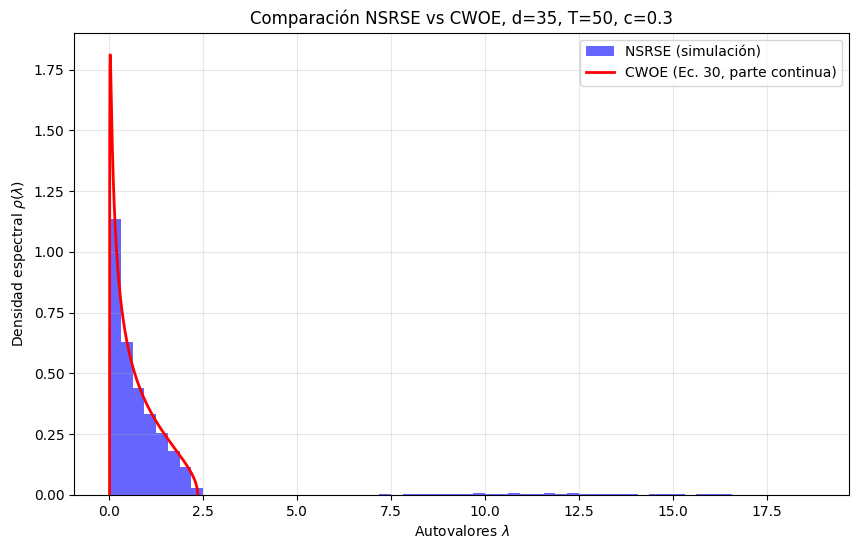

In [23]:

# Parámetros de las submatrices NSRSE
kappa = T / d

# Límites de la distribución teórica
lambda_menos = (1 - c) * (kappa**(-0.5) - 1)**2
lambda_mas = (1 - c) * (kappa**(-0.5) + 1)**2

# Valores para representar la curva teórica
lambdas = np.linspace(lambda_menos, lambda_mas, 1000)

# Evaluamos la densidad teórica
rho = rho_teorica(lambdas, c, kappa)

# Representamos el histograma y la distribución teórica
plt.figure(figsize=(10, 6))

plt.hist(autovalores, bins=60, density=True, color="blue", alpha=0.6, label="NSRSE (simulación)")

plt.plot(lambdas, rho, color="red", linewidth=2, label="CWOE (Ec. 30, parte continua)")

plt.xlabel(r"Autovalores $\lambda$")
plt.ylabel(r"Densidad espectral $\rho(\lambda)$")
plt.title(f"Comparación NSRSE vs CWOE, d={d}, T={T}, c={c}")

plt.legend()
plt.grid(alpha=0.3)
plt.show()




En la gráfica se compara la distribución numérica de autovalores del ensamble NSRSE de dimensión \(d=35\) con la densidad espectral teórica del CWOE, descrita por la ecuación (30) del artículo *Phys. Rev. E 88, 032115 (2013)*, utilizando los parámetros \(T=50\) y \(c=0.3\).

Se observa que la distribución numérica presenta una buena concordancia cualitativa con la predicción teórica en la región principal del espectro (*bulk*). Ambas distribuciones muestran una mayor concentración de autovalores cercanos a cero y una disminución progresiva de la densidad conforme aumenta el valor de \(\lambda\).

Sin embargo, también se observan autovalores aislados en la región de valores grandes, aproximadamente entre \(\lambda=7\) y \(\lambda=19\), que no son descritos por la parte continua de la distribución teórica. Estos autovalores están asociados con la presencia de correlaciones entre las variables y son compatibles con la aparición de un modo colectivo, representado mediante el término delta de Dirac en la ecuación (30).

Las diferencias entre el histograma y la curva teórica pueden atribuirse, en parte, a los efectos de dimensión finita y a las fluctuaciones estadísticas de las realizaciones del ensamble.